# Preprocessing dan Customer Segmentation dengan Clustering — Superstore

**Tujuan:** memeriksa kualitas data, membersihkan dataset, melakukan eksplorasi singkat, membentuk fitur pelanggan, lalu menerapkan clustering K-Means dan menginterpretasikan hasilnya.

**Dataset:** `Superstore_Modifikasi(1).xlsx` — sheet `Data_Modifikasi`.


1. Persiapan library dan konfigurasi
Cell kode berikut akan memeriksa library secara otomatis. Jika ada yang belum tersedia, notebook mencoba memasangnya ke folder lokal

In [1]:
from pathlib import Path
import sys
import subprocess
import importlib.util

PACKAGE_DIR = Path(".notebook_packages").resolve()
PACKAGE_DIR.mkdir(exist_ok=True)
# Prioritaskan library lokal notebook agar tidak bergantung pada kernel Python sistem
if str(PACKAGE_DIR) not in sys.path:
    sys.path.insert(0, str(PACKAGE_DIR))

required_modules = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn",
    "openpyxl": "openpyxl",
    "ipykernel": "ipykernel",
}
missing = [package for module, package in required_modules.items()
           if importlib.util.find_spec(module) is None]

if missing:
    print("Library belum tersedia:", ", ".join(missing))
    print("Menginstal library ke folder lokal notebook. Proses ini perlu koneksi internet dan dapat memerlukan beberapa menit...")
    command = [
        sys.executable, "-m", "pip", "install",
        "--disable-pip-version-check",
        "--target", str(PACKAGE_DIR),
        "numpy", "pandas", "matplotlib", "seaborn",
        "scikit-learn", "openpyxl", "ipykernel"
    ]
    result = subprocess.run(command, text=True)
    if result.returncode != 0:
        raise RuntimeError(
            "Instalasi otomatis gagal. Pastikan internet aktif. "
            "Alternatif yang disarankan: buat virtual environment (.venv) dan pilih kernel tersebut di VS Code."
        )
    if str(PACKAGE_DIR) not in sys.path:
        sys.path.insert(0, str(PACKAGE_DIR))

# Imports dilakukan setelah persiapan library
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

RANDOM_STATE = 42
DATA_PATH = Path("Superstore_Modifikasi(1).xlsx")
SHEET_NAME = "Data_Modifikasi"

if not DATA_PATH.exists():
    candidates = list(Path(".").glob("*.xlsx"))
    if len(candidates) == 1:
        DATA_PATH = candidates[0]
    else:
        raise FileNotFoundError(
            f"File Excel tidak ditemukan. Letakkan 'Superstore_Modifikasi(1).xlsx' "
            "di folder yang sama dengan notebook. File Excel di folder kerja: "
            + (", ".join(p.name for p in candidates) if candidates else "(tidak ada)")
        )

print("Semua library berhasil diimpor.")
print("Python yang digunakan:", sys.executable)
print("File yang digunakan:", DATA_PATH.resolve())

Semua library berhasil diimpor.
Python yang digunakan: /usr/local/bin/python3
File yang digunakan: /Users/nikentriwardani/Desktop/BIG DATA /TUGAS 2/Superstore_Modifikasi.xlsx


## 2. Membaca data dan memahami struktur

In [2]:
df_raw = pd.read_excel(DATA_PATH, sheet_name=SHEET_NAME)
df = df_raw.copy()

print("Ukuran data:", df.shape)
display(df.head())
display(df.info())
display(df.describe(include="all").T)

Ukuran data: (10294, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,NaN,CA-2016-152156,NaT,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.0,41.9136
1,2.0,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.0,219.5820
2,3.0,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,17.0,NaN,NaN
3,4.0,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,NaN,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,NaN,NaN
4,5.0,NaN,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,NaN,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.2,2.5164


<class 'pandas.DataFrame'>
RangeIndex: 10294 entries, 0 to 10293
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9213 non-null   float64       
 1   Order ID       9277 non-null   str           
 2   Order Date     9248 non-null   datetime64[us]
 3   Ship Date      9221 non-null   datetime64[us]
 4   Ship Mode      9282 non-null   str           
 5   Customer ID    9314 non-null   str           
 6   Customer Name  9248 non-null   str           
 7   Segment        9258 non-null   str           
 8   Country        9226 non-null   str           
 9   City           9307 non-null   str           
 10  State          9261 non-null   str           
 11  Postal Code    9305 non-null   float64       
 12  Region         9278 non-null   str           
 13  Product ID     9220 non-null   str           
 14  Category       9268 non-null   str           
 15  Sub-Category   9287 non-null  

None

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Row ID,9213.0,NaN,NaN,NaN,4991.280256,2.0,2493.0,4984.0,7495.0,9994.0,2885.54732
Order ID,9277,4755,CA-2017-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9248,NaN,NaN,NaN,2016-04-29 15:11:40.692041,2014-01-03 00:00:00,2015-05-20 00:00:00,2016-06-26 00:00:00,2017-05-14 00:00:00,2017-12-30 00:00:00,NaN
Ship Date,9221,NaN,NaN,NaN,2016-05-01 20:17:27.868994,2014-01-07 00:00:00,2015-05-22 00:00:00,2016-06-28 00:00:00,2017-05-14 00:00:00,2018-01-05 00:00:00,NaN
Ship Mode,9282,4,Standard Class,5519,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9314,792,WB-21850,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9248,792,Matt Abelman,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9258,3,Consumer,4809,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9226,1,United States,9226,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9307,526,New York City,832,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Audit kualitas data sebelum preprocessing

In [3]:
audit = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str),
    "unique_values": df.nunique(dropna=True)
}).sort_values("missing_count", ascending=False)

print("Jumlah baris duplikat penuh:", int(df.duplicated().sum()))
display(audit)
display(df[df.isna().any(axis=1)].head(10))

Jumlah baris duplikat penuh: 300


,missing_count,missing_percent,dtype,unique_values
Row ID,1081,10.50,float64,8953
Product ID,1074,10.43,str,1850
Ship Date,1073,10.42,datetime64[us],1320
Country,1068,10.37,str,1
Discount,1062,10.32,float64,14
Order Date,1046,10.16,datetime64[us],1225
Customer Name,1046,10.16,str,792
Profit,1042,10.12,float64,6521
Segment,1036,10.06,str,3
State,1033,10.03,str,49


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,NaN,CA-2016-152156,NaT,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.0,41.9136
2,3.0,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,17.0,NaN,NaN
3,4.0,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,NaN,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,NaN,NaN
4,5.0,NaN,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,NaN,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.2,2.5164
5,6.0,CA-2014-115812,NaT,NaT,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032.0,NaN,FUR-FU-10001487,Furniture,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.8600,7.0,0.0,14.1694
6,7.0,CA-2014-115812,2014-06-09,2014-06-14,NaN,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032.0,NaN,OFF-AR-10002833,Office Supplies,Art,Newell 322,7.2800,4.0,0.0,1.9656
7,8.0,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032.0,West,TEC-PH-10002275,Technology,Phones,Mitel 5320 IP Phone VoIP phone,907.1520,6.0,-0.8,NaN
8,9.0,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032.0,West,OFF-BI-10003910,Office Supplies,Binders,NaN,NaN,3.0,NaN,5.7825
9,10.0,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,90032.0,NaN,NaN,Office Supplies,Appliances,Belkin F5C206VTEL 6 Outlet Surge,114.9000,5.0,0.0,NaN
10,11.0,NaN,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,...,NaN,West,FUR-TA-10001539,Furniture,Tables,Chromcraft Rectangular Conference Tables,1706.1840,9.0,0.2,85.3092


## 4. Preprocessing dan tindakan penyelesaian

Langkah yang diterapkan:
- Menghapus duplikat penuh.
- Mengubah kolom tanggal menjadi tipe datetime.
- Mengubah kolom numerik yang relevan menjadi numerik.
- Mengisi `Postal Code` yang kosong menggunakan modus berdasarkan `City` bila tersedia, lalu modus keseluruhan. Kode pos diperlakukan sebagai kategori, bukan nilai untuk clustering.
- Mengisi kategori teks yang kosong dengan modus kolom (atau `Unknown` bila tidak ada modus).
- Memeriksa nilai numerik yang tidak masuk akal. Nilai `Sales`, `Quantity`, `Discount`, dan `Profit` tidak dihapus otomatis hanya karena ekstrem; transaksi rugi/discount tinggi bisa valid. Baris dengan tanggal atau ID pelanggan kosong akan dikeluarkan hanya dari analisis clustering pelanggan bila dibutuhkan, bukan otomatis dari data bersih.
- Menyimpan dataset bersih sebagai file baru.

In [4]:
# 4a. Hapus duplikat penuh
rows_before = len(df)
df = df.drop_duplicates().copy()
print(f"Duplikat dihapus: {rows_before - len(df):,}")

# 4b. Standarisasi nama kolom (hapus spasi di awal/akhir)
df.columns = df.columns.astype(str).str.strip()

# 4c. Konversi tipe data
date_cols = ["Order Date", "Ship Date"]
for col in date_cols:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

numeric_cols = ["Row ID", "Postal Code", "Sales", "Quantity", "Discount", "Profit"]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# 4d. Isi Postal Code dengan modus per City, lalu modus global
if "Postal Code" in df.columns:
    if "City" in df.columns:
        city_modes = df.groupby("City")["Postal Code"].agg(
            lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan
        )
        missing_postal = df["Postal Code"].isna()
        df.loc[missing_postal, "Postal Code"] = df.loc[missing_postal, "City"].map(city_modes)
    if df["Postal Code"].isna().any():
        postal_mode = df["Postal Code"].mode()
        if not postal_mode.empty:
            df["Postal Code"] = df["Postal Code"].fillna(postal_mode.iloc[0])

# 4e. Isi kolom kategori/teks kosong dengan modus; jika semua kosong, 'Unknown'
text_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
for col in text_cols:
    if df[col].isna().any():
        modes = df[col].mode(dropna=True)
        fill_value = modes.iloc[0] if not modes.empty else "Unknown"
        df[col] = df[col].fillna(fill_value)

# 4f. Laporan data setelah pembersihan
print("Ukuran setelah preprocessing:", df.shape)
print("Missing value tersisa:", int(df.isna().sum().sum()))
display(pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str)
}).sort_values("missing_count", ascending=False))
display(df.head())

Duplikat dihapus: 300
Ukuran setelah preprocessing: (9994, 21)
Missing value tersisa: 7097


,missing_count,missing_percent,dtype
Row ID,1041,10.42,float64
Ship Date,1041,10.42,datetime64[us]
Discount,1031,10.32,float64
Order Date,1024,10.25,datetime64[us]
Profit,1018,10.19,float64
Sales,996,9.97,float64
Quantity,946,9.47,float64
Customer ID,0,0.00,str
Customer Name,0,0.00,str
Segment,0,0.00,str


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,NaN,CA-2016-152156,NaT,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.0,41.9136
1,2.0,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.0,219.5820
2,3.0,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,17.0,NaN,NaN
3,4.0,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,NaN,NaN
4,5.0,CA-2017-100111,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.2,2.5164


## 5. Validasi dan eksplorasi data bersih

Catatan: nilai negatif pada `Profit` dapat menunjukkan kerugian dan tidak otomatis dihapus. `Discount` juga dipertahankan selama berada dalam rentang yang masuk akal.

,jumlah_baris
Sales <= 0,270
Quantity <= 0,257
"Discount di luar [0, 1]",1315
Profit negatif,1867


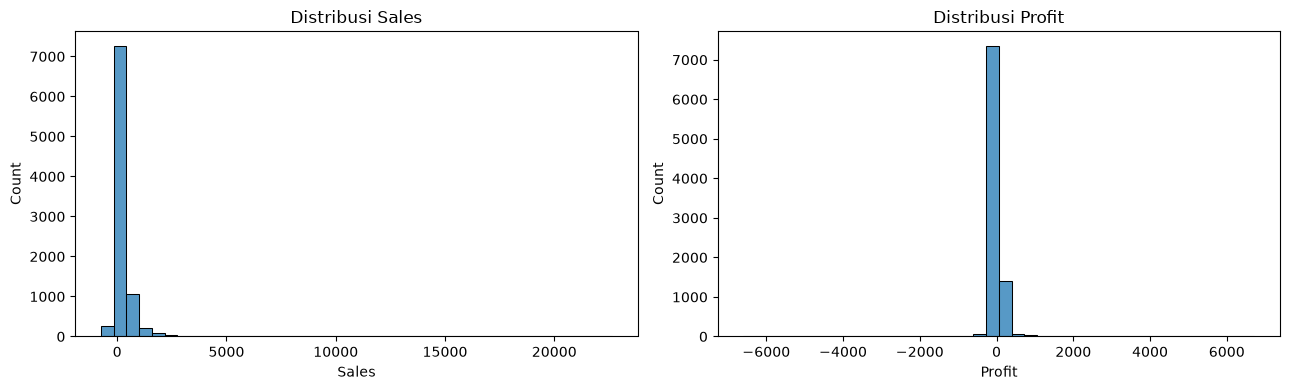

,total_sales,total_profit,total_quantity,transaction_rows
Category,,,,
Office Supplies,757322.7599,118672.13195,22083.0,6407
Technology,653999.8340,112298.07050,5614.0,1670
Furniture,585362.0839,16584.63690,6556.0,1917


In [5]:
# Pemeriksaan nilai penting
checks = {
    "Sales <= 0": int((df["Sales"] <= 0).sum()) if "Sales" in df else None,
    "Quantity <= 0": int((df["Quantity"] <= 0).sum()) if "Quantity" in df else None,
    "Discount di luar [0, 1]": int((~df["Discount"].between(0, 1)).sum()) if "Discount" in df else None,
    "Profit negatif": int((df["Profit"] < 0).sum()) if "Profit" in df else None,
}
display(pd.Series(checks, name="jumlah_baris").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["Sales"], bins=40, ax=axes[0])
axes[0].set_title("Distribusi Sales")
sns.histplot(df["Profit"], bins=40, ax=axes[1])
axes[1].set_title("Distribusi Profit")
plt.tight_layout()
plt.show()

if "Category" in df.columns and "Sales" in df.columns:
    display(df.groupby("Category", dropna=False).agg(
        total_sales=("Sales", "sum"),
        total_profit=("Profit", "sum"),
        total_quantity=("Quantity", "sum"),
        transaction_rows=("Order ID", "count")
    ).sort_values("total_sales", ascending=False))

## 6. Menyimpan dataset hasil preprocessing

Dataset bersih disimpan tanpa menimpa file Excel asli.

In [6]:
clean_path = Path("Superstore_Cleaned.csv")
df.to_csv(clean_path, index=False)
print("Dataset bersih disimpan ke:", clean_path.resolve())

Dataset bersih disimpan ke: /Users/nikentriwardani/Desktop/BIG DATA /TUGAS 2/Superstore_Cleaned.csv


## 7. Membentuk fitur pelanggan untuk clustering

Clustering dilakukan pada **level pelanggan**, bukan langsung pada setiap baris transaksi, supaya tiap pelanggan menjadi satu observasi. Fitur:
- `Recency`: jumlah hari sejak transaksi terakhir sampai tanggal acuan.
- `Frequency`: jumlah order unik pelanggan.
- `Monetary`: total penjualan pelanggan.
- `AvgOrderValue`: rata-rata penjualan per order.
- `TotalQuantity`, `AvgDiscount`, `TotalProfit`.

Tanggal acuan ditentukan satu hari setelah tanggal transaksi terakhir pada dataset. Nilai sangat menceng (skewed) pada fitur uang/frekuensi ditangani dengan `log1p` sebelum scaling.

In [7]:
required = ["Customer ID", "Order ID", "Order Date", "Sales", "Quantity", "Discount", "Profit"]
missing_required = [c for c in required if c not in df.columns]
if missing_required:
    raise ValueError(f"Kolom yang diperlukan tidak ditemukan: {missing_required}")

# Customer ID kosong tidak bisa dipakai untuk segmentasi pelanggan
customer_df = df.dropna(subset=["Customer ID", "Order Date"]).copy()
customer_df["Customer ID"] = customer_df["Customer ID"].astype(str).str.strip()
customer_df = customer_df[customer_df["Customer ID"].ne("")]

reference_date = customer_df["Order Date"].max().normalize() + pd.Timedelta(days=1)

customer_features = customer_df.groupby("Customer ID").agg(
    LastOrderDate=("Order Date", "max"),
    Frequency=("Order ID", "nunique"),
    Monetary=("Sales", "sum"),
    TotalQuantity=("Quantity", "sum"),
    AvgDiscount=("Discount", "mean"),
    TotalProfit=("Profit", "sum"),
    TransactionRows=("Order ID", "size")
).reset_index()

customer_features["Recency"] = (
    reference_date - customer_features["LastOrderDate"].dt.normalize()
).dt.days
customer_features["AvgOrderValue"] = (
    customer_features["Monetary"] / customer_features["Frequency"].replace(0, np.nan)
)
customer_features["AvgOrderValue"] = customer_features["AvgOrderValue"].fillna(0)

feature_cols = [
    "Recency", "Frequency", "Monetary", "AvgOrderValue",
    "TotalQuantity", "AvgDiscount", "TotalProfit"
]
customer_features[feature_cols] = customer_features[feature_cols].replace([np.inf, -np.inf], np.nan)
customer_features[feature_cols] = customer_features[feature_cols].fillna(0)

print("Tanggal acuan Recency:", reference_date.date())
print("Jumlah pelanggan untuk clustering:", len(customer_features))
display(customer_features.head())
display(customer_features[feature_cols].describe().T)

Tanggal acuan Recency: 2017-12-31
Jumlah pelanggan untuk clustering: 790


,Customer ID,LastOrderDate,Frequency,Monetary,TotalQuantity,AvgDiscount,TotalProfit,TransactionRows,Recency,AvgOrderValue
0,AA-10315,2017-06-29,4,3565.752,12.0,0.433333,-290.75560,6,185,891.438000
1,AA-10375,2017-12-11,8,851.916,21.0,0.000000,232.74150,12,20,106.489500
2,AA-10480,2016-08-26,3,779.240,12.0,0.000000,86.49915,7,492,259.746667
3,AA-10645,2017-11-05,7,4828.935,79.0,0.070833,783.72750,16,56,689.847857
4,AB-10015,2016-11-10,3,526.256,11.0,0.080000,205.01470,5,416,175.418667


,count,mean,std,min,25%,50%,75%,max
Recency,790.0,162.721519,200.010129,1.000,34.250000,85.000000,203.000000,1320.0000
Frequency,790.0,6.870886,25.664424,1.000,4.000000,6.000000,8.000000,724.0000
Monetary,790.0,2294.067708,7949.023638,-1477.846,621.095500,1560.886000,2818.999000,217420.3058
AvgOrderValue,790.0,340.232429,384.954815,-591.780,126.536616,264.648714,450.497083,5873.3890
TotalQuantity,790.0,38.903797,106.804612,-10.000,20.000000,32.000000,48.000000,2974.0000
AvgDiscount,790.0,0.156276,0.138512,-0.800,0.080000,0.150000,0.225000,1.0000
TotalProfit,790.0,289.480442,1034.793057,-6655.806,12.622525,160.584600,429.488512,20910.3773


## 8. Transformasi fitur dan pemilihan jumlah cluster

Fitur yang berskala sangat lebar ditransformasi `log1p` pada nilai non-negatif agar pengaruh outlier berkurang. Nilai fitur profit bisa negatif, sehingga digunakan transformasi signed-log: `sign(x) * log1p(abs(x))`. Setelah itu semua fitur distandardisasi.

,k,inertia,silhouette
0,2,4232.846379,0.559259
1,3,3368.747098,0.253778
2,4,2787.491999,0.283858
3,5,2483.766178,0.243288
4,6,2286.820481,0.223402
5,7,2104.991723,0.210805
6,8,1964.038696,0.210885


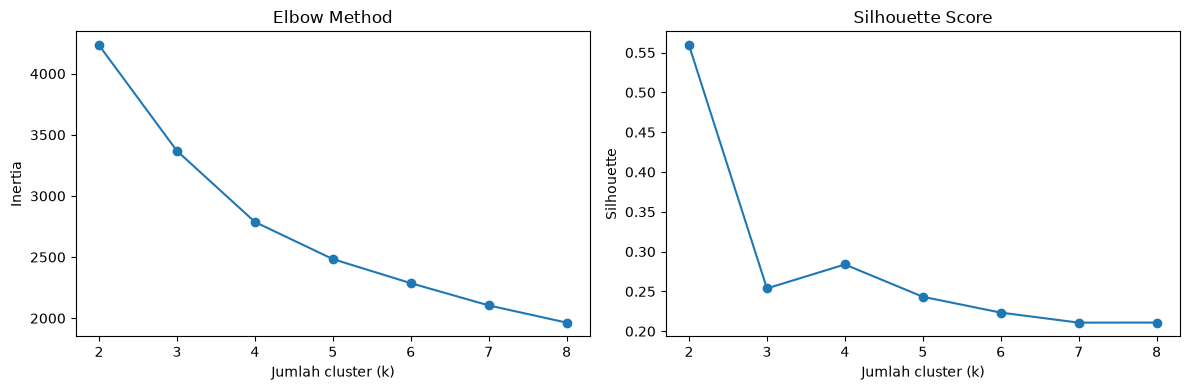

K terbaik berdasarkan silhouette pada rentang yang diuji: 2


In [8]:
X = customer_features[feature_cols].copy()

# Transformasi signed-log aman untuk fitur yang mungkin bernilai negatif
for col in X.columns:
    values = X[col].astype(float)
    if col == "AvgDiscount":
        # Discount berada pada skala kecil dan dipertahankan apa adanya
        continue
    X[col] = np.sign(values) * np.log1p(np.abs(values))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Elbow + silhouette untuk beberapa nilai k; silhouette dihitung pada sampel bila data besar
n_customers = len(customer_features)
if n_customers < 3:
    raise ValueError("Jumlah pelanggan terlalu sedikit untuk clustering (minimal 3).")

k_values = list(range(2, min(8, n_customers - 1) + 1))
inertias, silhouettes = [], []
sample_size = min(2000, n_customers)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    if len(np.unique(labels)) > 1:
        silhouettes.append(silhouette_score(
            X_scaled, labels, sample_size=sample_size if n_customers > sample_size else None,
            random_state=RANDOM_STATE
        ))
    else:
        silhouettes.append(np.nan)

metrics = pd.DataFrame({"k": k_values, "inertia": inertias, "silhouette": silhouettes})
display(metrics)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_values, inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Jumlah cluster (k)")
axes[0].set_ylabel("Inertia")
axes[1].plot(k_values, silhouettes, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Jumlah cluster (k)")
axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

# Pilih k dengan silhouette tertinggi sebagai titik awal; tetap evaluasi apakah profilnya masuk akal
best_k = int(metrics.loc[metrics["silhouette"].idxmax(), "k"])
print("K terbaik berdasarkan silhouette pada rentang yang diuji:", best_k)

## 9. Melatih K-Means dan melihat visualisasi PCA

Silhouette bukan satu-satunya pertimbangan. Periksa ukuran cluster, karakteristik profil, dan apakah segmen mudah dijelaskan secara bisnis.

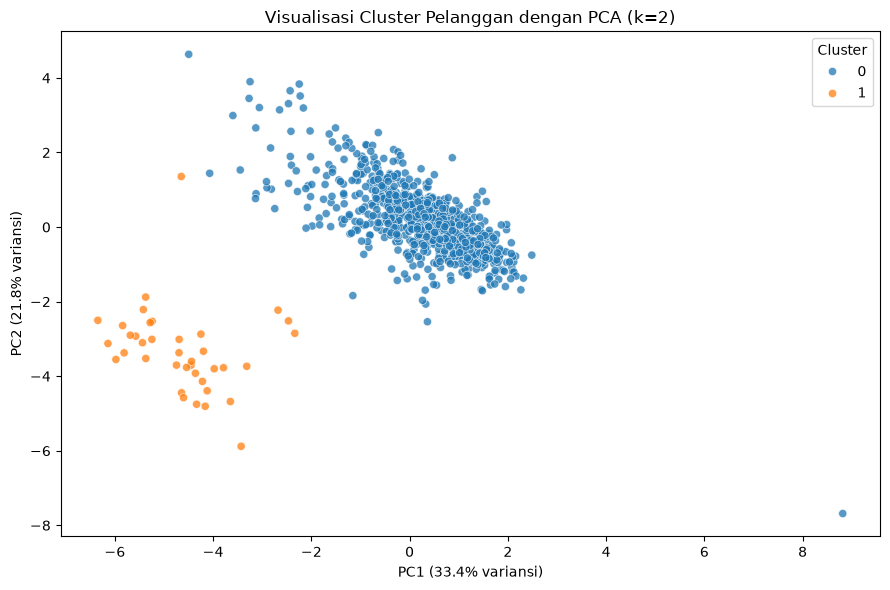

,jumlah_pelanggan
Cluster,
0,752
1,38


In [9]:
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=20)
customer_features["Cluster"] = kmeans.fit_predict(X_scaled)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_scaled)
plot_df = pd.DataFrame({
    "PC1": coords[:, 0],
    "PC2": coords[:, 1],
    "Cluster": customer_features["Cluster"].astype(str).values
})

plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="Cluster", alpha=0.75, s=35)
plt.title(f"Visualisasi Cluster Pelanggan dengan PCA (k={best_k})")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variansi)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variansi)")
plt.tight_layout()
plt.show()

display(customer_features["Cluster"].value_counts().sort_index().rename("jumlah_pelanggan").to_frame())

## 10. Profil dan interpretasi cluster

Tabel profil berikut menggunakan nilai asli agar mudah diterjemahkan ke konteks bisnis. Gunakan hasil aktual notebook untuk menamai cluster (misalnya pelanggan bernilai tinggi, pelanggan baru/aktif, atau pelanggan berisiko tidak kembali); jangan memberi nama sebelum melihat angka profil.

,JumlahPelanggan,Recency_Rata2,Frequency_Rata2,Monetary_Rata2,Monetary_Median,AvgOrderValue_Rata2,TotalQuantity_Rata2,AvgDiscount_Rata2,TotalProfit_Rata2,PersentasePelanggan
Cluster,,,,,,,,,,
0,752,159.79,6.95,2431.72,1651.84,362.56,39.49,0.15,296.41,95.19
1,38,220.66,5.21,-430.09,-373.05,-101.65,27.21,0.19,152.38,4.81


,Recency,Frequency,Monetary,AvgOrderValue,TotalQuantity,AvgDiscount,TotalProfit
Cluster,,,,,,,
0,159.79,6.95,2431.72,362.56,39.49,0.15,296.41
1,220.66,5.21,-430.09,-101.65,27.21,0.19,152.38


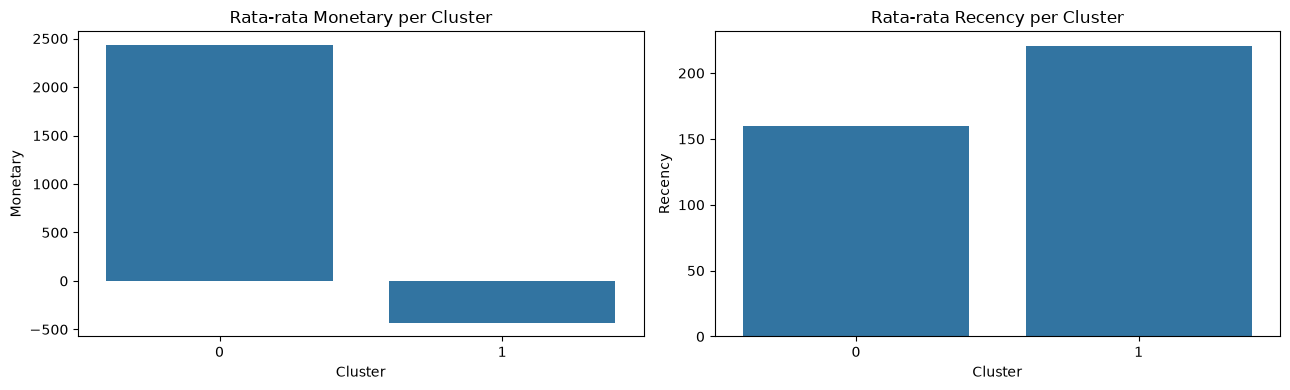

In [10]:
cluster_profile = customer_features.groupby("Cluster").agg(
    JumlahPelanggan=("Customer ID", "count"),
    Recency_Rata2=("Recency", "mean"),
    Frequency_Rata2=("Frequency", "mean"),
    Monetary_Rata2=("Monetary", "mean"),
    Monetary_Median=("Monetary", "median"),
    AvgOrderValue_Rata2=("AvgOrderValue", "mean"),
    TotalQuantity_Rata2=("TotalQuantity", "mean"),
    AvgDiscount_Rata2=("AvgDiscount", "mean"),
    TotalProfit_Rata2=("TotalProfit", "mean")
).round(2)

cluster_profile["PersentasePelanggan"] = (
    cluster_profile["JumlahPelanggan"] / len(customer_features) * 100
).round(2)
display(cluster_profile.sort_values("Monetary_Rata2", ascending=False))

# Visual ringkas rata-rata fitur per cluster
profile_for_plot = customer_features.groupby("Cluster")[feature_cols].mean()
display(profile_for_plot.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=customer_features, x="Cluster", y="Monetary", estimator=np.mean, errorbar=None, ax=axes[0])
axes[0].set_title("Rata-rata Monetary per Cluster")
sns.barplot(data=customer_features, x="Cluster", y="Recency", estimator=np.mean, errorbar=None, ax=axes[1])
axes[1].set_title("Rata-rata Recency per Cluster")
plt.tight_layout()
plt.show()

## 11. Menyimpan hasil clustering dan ringkasan

Dua file output utama:
- `Superstore_Customer_Clusters.csv`: fitur setiap pelanggan beserta label cluster.
- `Superstore_Cluster_Profile.csv`: ringkasan karakteristik masing-masing cluster.

In [11]:
clusters_path = Path("Superstore_Customer_Clusters.csv")
profile_path = Path("Superstore_Cluster_Profile.csv")

customer_features.to_csv(clusters_path, index=False)
cluster_profile.to_csv(profile_path, index=True)

print("Hasil clustering:", clusters_path.resolve())
print("Profil cluster:", profile_path.resolve())
display(customer_features.head(10))
display(cluster_profile)

Hasil clustering: /Users/nikentriwardani/Desktop/BIG DATA /TUGAS 2/Superstore_Customer_Clusters.csv
Profil cluster: /Users/nikentriwardani/Desktop/BIG DATA /TUGAS 2/Superstore_Cluster_Profile.csv


,Customer ID,LastOrderDate,Frequency,Monetary,TotalQuantity,AvgDiscount,TotalProfit,TransactionRows,Recency,AvgOrderValue,Cluster
0,AA-10315,2017-06-29,4,3565.752,12.0,0.433333,-290.75560,6,185,891.438000,0
1,AA-10375,2017-12-11,8,851.916,21.0,0.000000,232.74150,12,20,106.489500,0
2,AA-10480,2016-08-26,3,779.240,12.0,0.000000,86.49915,7,492,259.746667,0
3,AA-10645,2017-11-05,7,4828.935,79.0,0.070833,783.72750,16,56,689.847857,0
4,AB-10015,2016-11-10,3,526.256,11.0,0.080000,205.01470,5,416,175.418667,0
5,AB-10060,2017-11-06,8,6414.460,-4.0,-0.014286,1836.42530,15,55,801.807500,0
6,AB-10105,2017-11-19,9,13271.288,40.0,0.207692,5640.19300,14,42,1474.587556,0
7,AB-10150,2017-11-19,6,966.710,37.0,0.200000,318.97830,12,42,161.118333,0
8,AB-10165,2017-12-05,8,1964.666,40.0,0.130000,132.41860,12,26,245.583250,0
9,AB-10255,2017-07-17,9,129.072,47.0,0.163636,285.47255,14,167,14.341333,0


,JumlahPelanggan,Recency_Rata2,Frequency_Rata2,Monetary_Rata2,Monetary_Median,AvgOrderValue_Rata2,TotalQuantity_Rata2,AvgDiscount_Rata2,TotalProfit_Rata2,PersentasePelanggan
Cluster,,,,,,,,,,
0,752,159.79,6.95,2431.72,1651.84,362.56,39.49,0.15,296.41,95.19
1,38,220.66,5.21,-430.09,-373.05,-101.65,27.21,0.19,152.38,4.81


## 12. Kesimpulan untuk laporan tugas

Setelah menjalankan seluruh cell, tuliskan kesimpulan berdasarkan hasil yang benar-benar muncul:
1. **Kualitas data:** sebutkan jumlah baris awal, duplikat yang dihapus, dan missing value sebelum/sesudah preprocessing.
2. **Tindakan preprocessing:** jelaskan konversi tanggal/numerik, penanganan kode pos dan nilai kategori kosong, serta alasan nilai profit negatif tidak otomatis dihapus.
3. **Metode clustering:** K-Means dipilih karena membagi pelanggan berdasarkan kemiripan fitur; StandardScaler memastikan fitur berada pada skala sebanding.
4. **Pemilihan k:** laporkan nilai silhouette dan pola elbow, lalu jelaskan alasan memilih k.
5. **Interpretasi:** gunakan `cluster_profile` untuk menjelaskan karakteristik tiap cluster, bukan hanya nomor cluster.
6. **Keterbatasan:** hasil sensitif terhadap fitur, transformasi, dan nilai k; silhouette/elbow membantu memilih model tetapi tidak membuktikan bahwa segmen bisnis sudah sempurna.

**Catatan penting:** label cluster `0`, `1`, dan seterusnya bersifat arbitrer. Cluster 0 tidak otomatis lebih baik daripada cluster 1.